# Bias and MAPE for every frame (field)

A field has one CD, one CV and one HEX, so for a single field the error is a signed number and its MAPE is the same number without the sign. Table 1 prints both for every field, for both models, with an `all` row that averages the fields (there the error column is the bias and the MAPE column is the usual MAPE). Table 2 gives a real bias and MAPE inside each field, over its cells, for the Center Method: each of our cells is compared with the instrument's cell for the same marker. That needs equal cell counts, so fields where the counts differ are listed without cell statistics.

Cell 1 prints which `score_deks.py` and `patent_model.py` were loaded; both should be the project's copies. Restart the kernel after editing either. The tables are also saved to `frame_metrics.csv`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

PROJECT = Path(r"C:\2026_ECD_CV_HEX_CCD_Calculation")
sys.path.insert(0, str(PROJECT))      # use the project's scripts, not old copies elsewhere

import csv
import numpy as np
import matplotlib.pyplot as plt
import score_deks as sd
import patent_model as pm
print("using", sd.__file__, "and", pm.__file__)

ROOT = PROJECT / "SAMPLE - DEKS-EYEBANK" / "Reader1"
UM = 0.768
sd.MIN_PEELED = 99
P_EXP, A_OUTER, OUTER_D = 3.0, 100.0, "mid"   # best Center Method setting

using C:\2026_ECD_CV_HEX_CCD_Calculation\score_deks.py and C:\2026_ECD_CV_HEX_CCD_Calculation\patent_model.py


In [2]:
rows = []
for img, k, a_path, c_path in sd.frames(ROOT):
    areas, sides, _ = sd.read_A(a_path)
    pts, _, _ = sd.read_C(c_path)
    if len(areas) < sd.MIN_AREAS or len(pts) < sd.MIN_POINTS or sides is None:
        continue
    v = sd.analyse(pts, UM)                                                   # Voronoi, local weights
    c = pm.analyse_patent(pts, UM, P_EXP, A_OUTER, OUTER_D, "vertices")       # Center Method
    if v is None or c is None:
        continue
    row = dict(frame=f"{img}.{k}", num_gt=len(areas),
               cd_gt=1e6 / areas.mean(), cv_gt=areas.std(ddof=0) / areas.mean(), hex_gt=float((sides == 6).mean()),
               num_v=v["num"], cd_v=v["cd"], cv_v=v["cv_local"], hex_v=v["hex"],
               num_c=c["num"], cd_c=c["cd"], cv_c=c["cv"], hex_c=c["hex"],
               cells=np.nan, area_bias=np.nan, area_mape=np.nan, sides_ok=np.nan, r=np.nan, slope=np.nan)
    if c["num"] == len(areas):           # same count: pair the cells in marker order
        e = (c["areas_um2"] - areas) / areas
        row.update(cells=len(areas), area_bias=100 * e.mean(), area_mape=100 * np.abs(e).mean(),
                   sides_ok=100 * float((c["sides"] == sides).mean()),
                   r=float(np.corrcoef(c["areas_um2"], areas)[0, 1]),
                   slope=float(np.polyfit(c["areas_um2"], areas, 1)[0]))
    rows.append(row)
print(len(rows), "fields")

def pct(r, m, tag):
    """Error of one field in percent: (model - instrument) / instrument."""
    return 100 * (r[f"{m}_{tag}"] - r[f"{m}_gt"]) / r[f"{m}_gt"]

37 fields


In [3]:
# Table 1: for every field, the error in % (signed) and the MAPE in % (its size), for CD, CV and HEX.
# One field has one CD, one CV and one HEX, so its MAPE is just the size of its error. The last row averages all fields.
def show(tag, label):
    print(f"\n{label}")
    print(f"{'field':>6}{'Num inst':>9}{'Num':>5} | {'CD err%':>8}{'CD MAPE%':>9} | {'CV err%':>8}{'CV MAPE%':>9} | {'HEX err%':>9}{'HEX MAPE%':>10}")
    errs = []
    for r in rows:
        e = [pct(r, m, tag) for m in ("cd", "cv", "hex")]
        errs.append(e)
        print(f"{r['frame']:>6}{r['num_gt']:>9}{r['num_' + tag]:>5} | {e[0]:>+8.1f}{abs(e[0]):>9.1f} | "
              f"{e[1]:>+8.1f}{abs(e[1]):>9.1f} | {e[2]:>+9.1f}{abs(e[2]):>10.1f}")
    E = np.array(errs)
    print(f"{'all':>6}{'':>14} | {E[:, 0].mean():>+8.1f}{np.abs(E[:, 0]).mean():>9.1f} | "
          f"{E[:, 1].mean():>+8.1f}{np.abs(E[:, 1]).mean():>9.1f} | {E[:, 2].mean():>+9.1f}{np.abs(E[:, 2]).mean():>10.1f}")
    print("(all row: err% is the bias, the mean of the signed errors; MAPE% is the mean of their sizes)")

show("c", "Center Method")
show("v", "Voronoi (local weights)")


Center Method
 field Num inst  Num |  CD err% CD MAPE% |  CV err% CV MAPE% |  HEX err% HEX MAPE%
   2.1      101  101 |     +0.3      0.3 |     +0.2      0.2 |      +0.0       0.0
   2.2      103  103 |     +0.4      0.4 |     +0.4      0.4 |      -1.3       1.3
   2.3       62   61 |     +1.0      1.0 |     -1.5      1.5 |      +1.6       1.6
   3.1       88   88 |     +0.6      0.6 |     -0.1      0.1 |      +0.0       0.0
   3.2      129  128 |     +0.3      0.3 |     -0.3      0.3 |      +0.8       0.8
   3.3      103  102 |     +0.1      0.1 |     +0.5      0.5 |      +1.0       1.0
   5.1       71   71 |     +0.2      0.2 |     +1.4      1.4 |      +2.2       2.2
   5.2       54   54 |     +0.3      0.3 |     +1.0      1.0 |      +0.0       0.0
   5.3       55   55 |     +0.2      0.2 |     +1.6      1.6 |      +0.0       0.0
   6.1       96   96 |     +0.5      0.5 |     +0.9      0.9 |      +0.0       0.0
   6.2       77   77 |     +0.4      0.4 |     +1.0      1.0 |      +0.0

In [4]:
# Table 2: bias and MAPE inside each field, over its cells (Center Method). Needs equal cell counts to pair cells.
print("\nCell by cell inside each field (Center Method): area error = (our cell - instrument cell) / instrument cell")
print(f"{'field':>6}{'cells':>7}{'area bias%':>12}{'area MAPE%':>12}{'sides agree%':>14}{'r':>7}{'slope':>7}")
for r in rows:
    if np.isfinite(r["cells"]):
        print(f"{r['frame']:>6}{int(r['cells']):>7}{r['area_bias']:>+12.1f}{r['area_mape']:>12.1f}"
              f"{r['sides_ok']:>14.1f}{r['r']:>7.3f}{r['slope']:>7.2f}")
    else:
        print(f"{r['frame']:>6}   counts differ: ours {r['num_c']}, instrument {r['num_gt']} (cells cannot be paired)")

with open(PROJECT / "frame_metrics.csv", "w", newline="") as fh:
    cols = ["frame", "num_gt", "num_c", "num_v"] + [f"{m}_err_{t}" for m in ("cd", "cv", "hex") for t in ("c", "v")] \
           + [f"{m}_mape_{t}" for m in ("cd", "cv", "hex") for t in ("c", "v")] \
           + ["cells", "area_bias", "area_mape", "sides_ok", "r", "slope"]
    w = csv.DictWriter(fh, fieldnames=cols)
    w.writeheader()
    for r in rows:
        out = {k: r[k] for k in ("frame", "num_gt", "num_c", "num_v", "cells", "area_bias", "area_mape", "sides_ok", "r", "slope")}
        for m in ("cd", "cv", "hex"):
            for t in ("c", "v"):
                out[f"{m}_err_{t}"] = round(pct(r, m, t), 3)
                out[f"{m}_mape_{t}"] = round(abs(pct(r, m, t)), 3)
        w.writerow(out)
print("\nwrote", PROJECT / "frame_metrics.csv")


Cell by cell inside each field (Center Method): area error = (our cell - instrument cell) / instrument cell
 field  cells  area bias%  area MAPE%  sides agree%      r  slope
   2.1    101        -0.2         1.4         100.0  0.999   1.00
   2.2    103        -0.4         1.1          99.0  0.999   1.00
   2.3   counts differ: ours 61, instrument 62 (cells cannot be paired)
   3.1     88        -0.5         2.0          97.7  0.995   1.00
   3.2   counts differ: ours 128, instrument 129 (cells cannot be paired)
   3.3   counts differ: ours 102, instrument 103 (cells cannot be paired)
   5.1     71        -0.5         1.9          98.6  0.997   0.99
   5.2     54        -0.4         1.2         100.0  0.999   0.99
   5.3     55        -0.4         1.1         100.0  0.999   0.99
   6.1     96        -0.3         1.1         100.0  0.999   0.99
   6.2     77        -0.4         1.3         100.0  0.999   0.99
   6.3     36        -0.3         1.7          94.4  0.995   1.01
   7.1    1

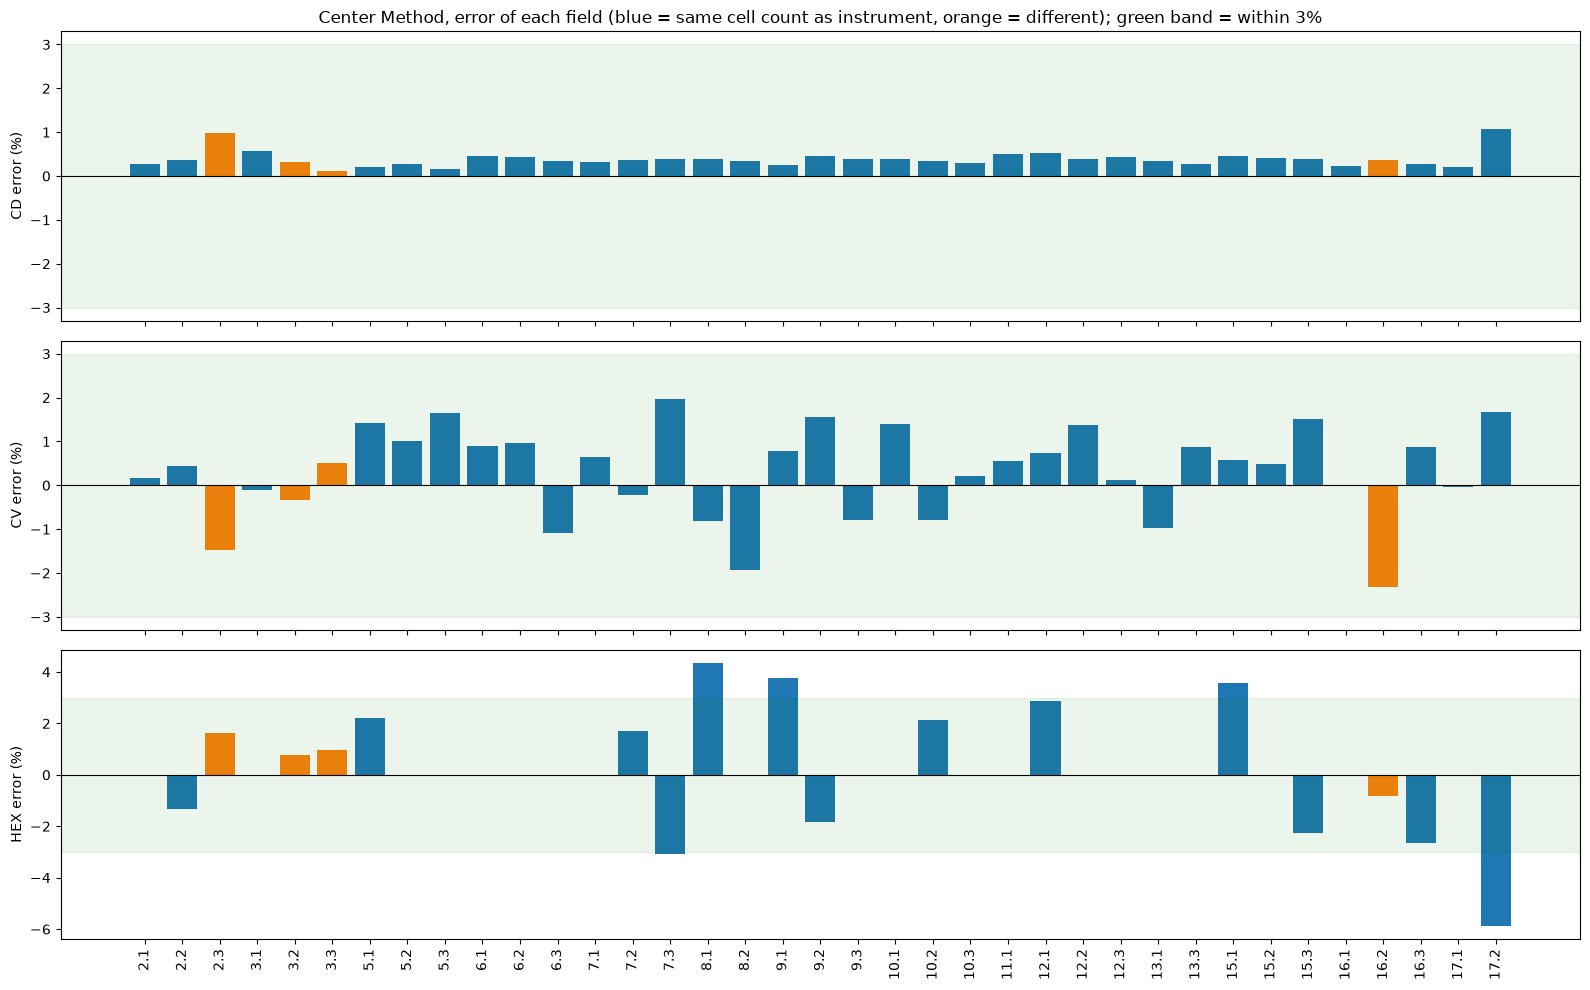

In [5]:
# Chart: error of each field for the Center Method. Orange = our cell count differs from the instrument's.
frames = [r["frame"] for r in rows]
x = np.arange(len(rows))
same = np.array([r["num_c"] == r["num_gt"] for r in rows])
fig, axs = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
for ax, (m, name) in zip(axs, (("cd", "CD"), ("cv", "CV"), ("hex", "HEX"))):
    vals = np.array([pct(r, m, "c") for r in rows])
    ax.bar(x, vals, color=np.where(same, "tab:blue", "tab:orange"))
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhspan(-3, 3, color="green", alpha=0.08)
    ax.set_ylabel(f"{name} error (%)")
axs[-1].set_xticks(x)
axs[-1].set_xticklabels(frames, rotation=90)
axs[0].set_title("Center Method, error of each field (blue = same cell count as instrument, orange = different); green band = within 3%")
plt.tight_layout()
plt.show()